<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week6/lesson22/Lesson22_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 22 — Leaky Integrate-and-Fire Neurons: Threshold, Reset, F–I Curves and Noise

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 6 — Differential Equations\
**Lesson:** Lesson 22\
**Notebook type:** Teaching notebook

> *"The leaky integrate-and-fire neuron is a differential equation with a rule for breaking it."*

---

### From a membrane to a neuron

Lesson 21's passive membrane integrates its input and leaks, but it never fires: its voltage relaxes smoothly to $E_L + R_m I$, however large $I$ is. Real neurons fire an action potential when their voltage reaches about −50 to −35 mV, then reset and recover. The **leaky integrate-and-fire** (LIF) model keeps the passive equation below threshold and adds that event **by hand**: no ion channels, just a rule.

We will see:
1. the LIF model: passive subthreshold dynamics plus an **event condition** (threshold, spike, reset, refractory period);
2. **rheobase**, the **interspike interval** formula and the **F–I curve**, derived and simulated;
3. **deterministic versus stochastic drive**: Gaussian (diffusion) noise and Poisson synaptic input, and the irregular spike trains they produce;
4. **event handling and time-step sensitivity**: how a simulator detects and times spikes, and why the noise term must scale with $\sqrt{\Delta t}$;
5. a mini-lab that compares the LIF with the spiking sweeps of Lesson 21's neuron, and finds out what the model leaves out.

The mini-lab reuses the whole-cell recording from the pyABF sample files (MIT licence) used in Lesson 21. Lesson 23 moves from single neurons to coupled populations.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.optimize import least_squares

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-21.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-21.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: What the Membrane Equation Cannot Do**

In Lesson 21 the passive membrane fitted the neuron's response to −100 pA almost perfectly. But from 70 pA the neuron **fired action potentials**, and the membrane equation, whose solution approaches $E_L + R_m I$ monotonically, cannot produce a spike at any current.

**Retrieval.**
- The passive response to a step is $V(t) = V_\infty + (E_L - V_\infty)e^{-t/\tau_m}$ with $V_\infty = E_L + R_m I$ (Lesson 21).
- So the time to climb from $E_L$ to any level $\theta < V_\infty$ is $t = \tau_m \ln\dfrac{V_\infty - E_L}{V_\infty - \theta}$ (solve for $t$, Lesson 8).

**Prediction before running:** if a neuron fires whenever $V$ reaches a threshold $\theta$ and then restarts from a reset value, how should its firing rate depend on the current? Linearly? Is there a smallest current that makes it fire at all?

# **Part 1: The Leaky Integrate-and-Fire Model**

The LIF neuron (Lapicque, 1907, in modern form) has two parts.

**Subthreshold dynamics** — the passive membrane of Lesson 21:
$$\tau_m \frac{dV}{dt} = -(V - E_L) + R_m I(t).$$

**Event condition** — when $V$ reaches the threshold $\theta$ at time $t_k$:
1. record a **spike** at $t_k$ (the action potential itself is not modelled; it is replaced by an instant);
2. **reset** the voltage: $V \leftarrow V_{\text{reset}}$;
3. hold it there for an **absolute refractory period** $t_{\text{ref}}$ (no integration, no spikes).

The model is a **hybrid system**: a continuous ODE between events, and a discontinuous jump at each event. The ODE alone never reaches $\theta$ unless $V_\infty > \theta$, so the event rule is what turns "enough current" into a spike train.

**Parameters used below** (typical of a cortical pyramidal neuron): $E_L = -70$ mV, $\theta = -50$ mV, $V_{\text{reset}} = -65$ mV, $\tau_m = 20$ ms, $R_m = 100$ MΩ (so $R_m I$ in mV is $0.1 \times I$ in pA), $t_{\text{ref}} = 2$ ms.

I = 150 pA: no spikes
I = 250 pA: 6 spikes, first 32.2 ms after onset, ISIs [29.7, 29.7, 29.7] ms
I = 400 pA: 15 spikes, first 13.9 ms after onset, ISIs [13.2, 13.2, 13.2] ms


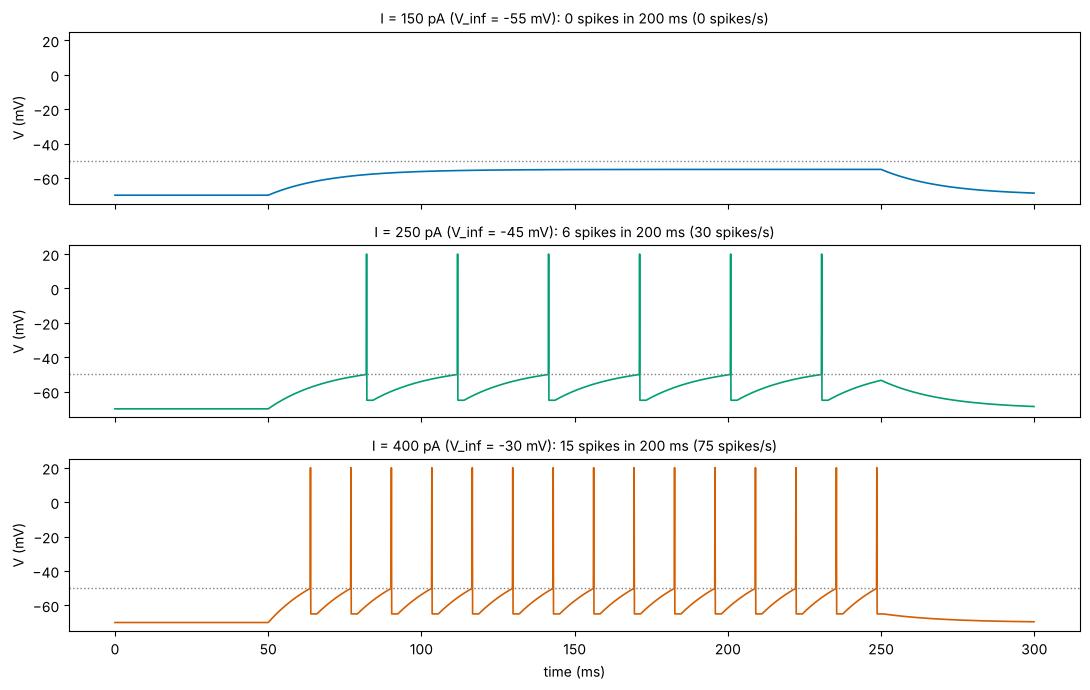

In [3]:
P = dict(E_L=-70.0, theta=-50.0, V_reset=-65.0, tau=20.0, R=0.1, t_ref=2.0)    # mV, mV, mV, ms, mV/pA (100 megaohm), ms

def simulate_lif(I, dt, E_L=-70.0, theta=-50.0, V_reset=-65.0, tau=20.0, R=0.1, t_ref=2.0, V0=None, sigma=0.0, rng=None):
    # Euler simulation of the LIF neuron.
    # I: (n_steps,) injected current, pA, one value per time step of dt ms.
    # sigma: SD (mV) of Gaussian membrane noise (Euler-Maruyama; see Part 3).
    # Returns V (n_steps,) in mV with spikes drawn as a vertical line to 0 mV, and spike times (ms).
    n = len(I); V = np.empty(n); V[0] = E_L if V0 is None else V0
    spikes, ref_until = [], -np.inf
    noise = (rng.standard_normal(n) * sigma * np.sqrt(2 * dt / tau)) if sigma > 0 else np.zeros(n)
    for k in range(n - 1):
        t = k * dt
        if t < ref_until:                                                   # refractory: clamp at reset
            V[k + 1] = V_reset
            continue
        V[k + 1] = V[k] + dt / tau * (-(V[k] - E_L) + R * I[k]) + noise[k]
        if V[k + 1] >= theta:                                               # event: spike, reset, refractory
            spikes.append((k + 1) * dt)
            V[k] = max(V[k], theta); V[k + 1] = V_reset                     # draw the spike as reaching threshold, then reset
            ref_until = (k + 1) * dt + t_ref
    return V, np.array(spikes)

dt = 0.1                                                                    # ms
t = np.arange(0, 300, dt)                                                   # (3000,) ms
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, I_amp, c in zip(axes, [150, 250, 400], [PALETTE[0], PALETTE[2], PALETTE[1]]):
    I = np.where((t >= 50) & (t < 250), I_amp, 0.0)                         # (3000,) pA
    V, sp = simulate_lif(I, dt, **P)
    Vplot = V.copy(); Vplot[np.searchsorted(t, sp) - 1] = 20.0               # draw spikes as tall lines for display
    ax.plot(t, Vplot, color=c, lw=1.2)
    ax.axhline(P['theta'], color='grey', ls=':', lw=1)
    ax.set_ylabel('V (mV)'); ax.set_ylim(-75, 25)
    rate = len(sp) / 0.2
    ax.set_title(f'I = {I_amp} pA (V_inf = {P["E_L"] + P["R"] * I_amp:.0f} mV): {len(sp)} spikes in 200 ms ({rate:.0f} spikes/s)', fontsize=10)
    if len(sp):
        print(f"I = {I_amp} pA: {len(sp)} spikes, first {sp[0] - 50:.1f} ms after onset, ISIs {np.round(np.diff(sp), 2).tolist()[:3]} ms")
    else:
        print(f"I = {I_amp} pA: no spikes")
axes[-1].set_xlabel('time (ms)')
plt.tight_layout(); plt.show()

- **150 pA:** $V_\infty = -55$ mV is below threshold. The neuron charges exactly like Lesson 21's membrane and never fires.
- **250 pA:** $V_\infty = -45$ mV is above threshold. The voltage climbs, crosses −50 mV, resets to −65 mV, and climbs again: a perfectly **regular** spike train.
- **400 pA:** the climb is steeper, so the intervals are shorter and the rate higher.

Every interspike interval at a fixed current is identical: with constant input, the LIF is a deterministic clock. The interval is set by how long the passive membrane takes to climb from $V_{\text{reset}}$ to $\theta$, plus $t_{\text{ref}}$; Part 2 computes it exactly.

# **Part 2: Rheobase, Interspike Interval and the F–I Curve**

**Rheobase.** The smallest constant current that makes the neuron fire. The neuron fires if and only if $V_\infty = E_L + R_m I > \theta$, so

$$I_{\text{rh}} = \frac{\theta - E_L}{R_m}.$$

Here $(−50 − (−70))/0.1 = 200$ pA.

**Interspike interval.** Above rheobase, after a reset the voltage follows $V(t) = V_\infty + (V_{\text{reset}} - V_\infty)e^{-t/\tau_m}$ (Lesson 21). Setting $V(T) = \theta$ and solving for $T$:

$$T_{\text{ISI}}(I) = t_{\text{ref}} + \tau_m \ln\frac{V_\infty - V_{\text{reset}}}{V_\infty - \theta}, \qquad V_\infty = E_L + R_m I.$$

**F–I curve.** The firing rate is $f(I) = 1/T_{\text{ISI}}(I)$ for $I > I_{\text{rh}}$ and 0 otherwise. Its shape:
- **near rheobase**, $V_\infty - \theta \to 0^+$, the logarithm diverges, so $T \to \infty$ and $f \to 0$ continuously, but with infinite slope (the rate rises very steeply just above rheobase);
- **for large currents**, $\ln\frac{V_\infty - V_{\text{reset}}}{V_\infty - \theta} \approx \frac{\theta - V_{\text{reset}}}{V_\infty}$, so $f$ grows roughly linearly with $I$, and is capped at $1/t_{\text{ref}}$ (500 spikes/s here).

A neuron whose rate rises continuously from 0 at rheobase is called **type I** (Hodgkin's classification); one that jumps to a non-zero rate is **type II**.

rheobase = (theta - E_L) / R = 200 pA


 I (pA)  formula (spikes/s)  simulation, dt = 0.01 ms
    150                0.00                      0.00
    199                0.00                      0.00
    201                9.77                      9.77
    210               17.41                     17.41
    250               33.64                     33.65
    300               49.20                     49.19
    400               75.80                     75.82
    600              119.49                    119.47
    800              154.73                    154.56
   1000              183.92                    183.82


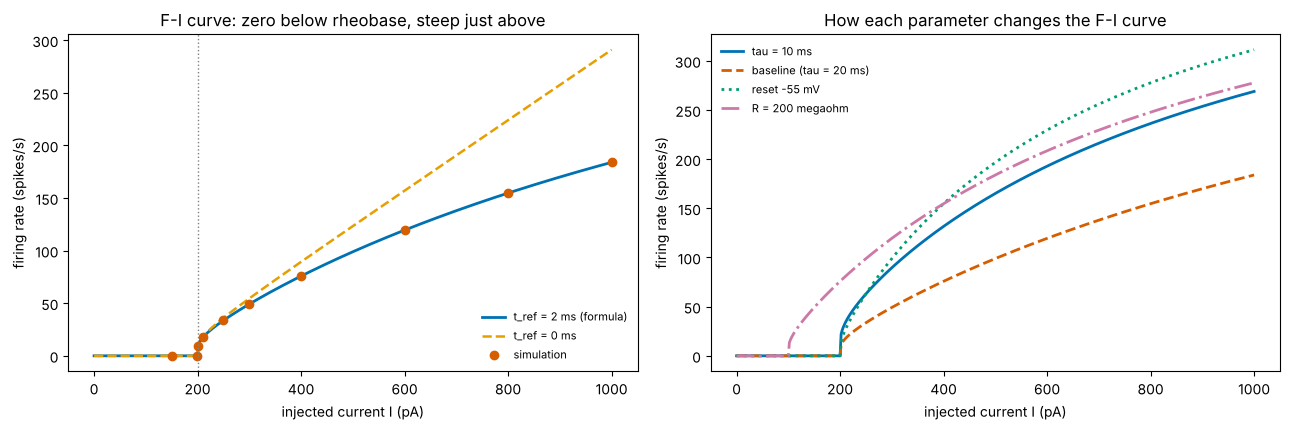

In [4]:
def lif_rate(I, E_L=-70.0, theta=-50.0, V_reset=-65.0, tau=20.0, R=0.1, t_ref=2.0):
    # Analytical F-I curve (spikes/s) of the deterministic LIF; I in pA, times in ms.
    I = np.asarray(I, float); V_inf = E_L + R * I
    rate = np.zeros_like(I)
    ok = V_inf > theta
    rate[ok] = 1000.0 / (t_ref + tau * np.log((V_inf[ok] - V_reset) / (V_inf[ok] - theta)))
    return rate

I_rh = (P['theta'] - P['E_L']) / P['R']
print(f"rheobase = (theta - E_L) / R = {I_rh:.0f} pA")
I_grid = np.linspace(0, 1000, 501)                                          # (501,) pA
I_sim = np.array([150, 199, 201, 210, 250, 300, 400, 600, 800, 1000])       # (10,) pA
t_long = np.arange(0, 2000, 0.01)                                           # (200000,) ms, fine step for this check
rate_sim = []
for I_amp in I_sim:
    V, sp = simulate_lif(np.full(t_long.size, I_amp), 0.01, **P)
    rate_sim.append((len(sp) - 1) / (sp[-1] - sp[0]) * 1000 if len(sp) > 1 else 0.0)
rate_sim = np.array(rate_sim)
print(f"{'I (pA)':>7}{'formula (spikes/s)':>20}{'simulation, dt = 0.01 ms':>26}")
for I_amp, rs in zip(I_sim, rate_sim):
    print(f"{I_amp:>7}{lif_rate(I_amp, **P):>20.2f}{rs:>26.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
axes[0].plot(I_grid, lif_rate(I_grid, **P), color=PALETTE[0], lw=2, label='t_ref = 2 ms (formula)')
axes[0].plot(I_grid, lif_rate(I_grid, **{**P, 't_ref': 0.0}), '--', color=PALETTE[4], lw=1.8, label='t_ref = 0 ms')
axes[0].plot(I_sim, rate_sim, 'o', color=PALETTE[1], ms=6, label='simulation')
axes[0].axvline(I_rh, color='grey', ls=':', lw=1)
axes[0].set_xlabel('injected current I (pA)'); axes[0].set_ylabel('firing rate (spikes/s)'); axes[0].set_title('F-I curve: zero below rheobase, steep just above')
axes[0].legend(frameon=False, fontsize=8)
for k, (lab, kw) in enumerate([('tau = 10 ms', dict(tau=10.0)), ('baseline (tau = 20 ms)', {}), ('reset -55 mV', dict(V_reset=-55.0)), ('R = 200 megaohm', dict(R=0.2))]):
    axes[1].plot(I_grid, lif_rate(I_grid, **{**P, **kw}), ls=LINESTYLES[k], color=PALETTE[k], lw=2, label=lab)
axes[1].set_xlabel('injected current I (pA)'); axes[1].set_ylabel('firing rate (spikes/s)'); axes[1].set_title('How each parameter changes the F-I curve')
axes[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

- Simulation with a fine step agrees with the formula; just above rheobase (201 pA) the rate is already about 10 spikes/s, and 9 pA more brings it to 17 spikes/s.
- **Larger $R_m$** lowers the rheobase (the same current moves the voltage further). **Shorter $\tau_m$** makes the climb faster: higher rates, same rheobase. A **reset closer to threshold** shortens every interval. **Refractoriness** bends the curve over at high currents.
- The F–I curve of the LIF is the prototype of the **activation function** of artificial neural networks (Lesson 8): a threshold followed by a rising, saturating rate. Its shape near threshold is set by the logarithm, not chosen.

#### Interactive version: the spike train as the current changes

In [5]:
I_list = [180, 200, 205, 220, 250, 300, 400, 600]
t_i = np.arange(0, 300, 0.1)                                                 # (3000,) ms
def trace_for(I_amp):
    I = np.where(t_i >= 50, float(I_amp), 0.0)
    V, sp = simulate_lif(I, 0.1, **P)
    Vplot = V.copy(); Vplot[np.searchsorted(t_i, sp) - 1] = 20.0
    return Vplot, sp
V0p, sp0 = trace_for(I_list[0])
fig_i = go.Figure([go.Scatter(x=t_i, y=np.round(V0p, 2), mode='lines', line=dict(color=PALETTE[0], width=1.5), name='V'),
                   go.Scatter(x=[0, 300], y=[P['theta']] * 2, mode='lines', line=dict(color='grey', dash='dot'), name='threshold')])
frames = []
for i, I_amp in enumerate(I_list):
    Vp, sp = trace_for(I_amp)
    frames.append(go.Frame(name=str(i), traces=[0], data=[go.Scatter(y=np.round(Vp, 2))],
                           layout=go.Layout(title=f'I = {I_amp} pA: formula {lif_rate(I_amp, **P):.1f} spikes/s;  {len(sp)} spikes in 250 ms')))
fig_i.frames = frames
buttons, sliders = play_pause_and_slider(I_list, prefix='I (pA) = ', duration=700)
fig_i.update_layout(title=frames[0].layout.title.text, xaxis=dict(title='time (ms)'), yaxis=dict(title='V (mV)', range=[-75, 25]),
                    template='plotly_white', width=850, height=450, updatemenus=buttons, sliders=sliders)
fig_i.show(config=PLOTLY_CONFIG)

# **Part 3: Deterministic versus Stochastic Drive**

A neuron in the brain does not receive a clean current step. It receives thousands of synaptic inputs that arrive at random times (Lesson 18's Poisson processes). Two standard ways to model this:

**Gaussian (diffusion) drive.** Add white noise to the membrane equation:
$$\tau_m \frac{dV}{dt} = -(V - E_L) + R_m I + \sigma\sqrt{2\tau_m}\,\xi(t),$$
where $\xi(t)$ is Gaussian white noise. Without threshold, $V$ is an **Ornstein–Uhlenbeck process**: it fluctuates around $E_L + R_m I$ with standard deviation $\sigma$ (mV). In a simulation with step $\Delta t$ the noise enters as

$$V_{n+1} = V_n + \frac{\Delta t}{\tau_m}\big(-(V_n - E_L) + R_m I_n\big) + \sigma\sqrt{\frac{2\Delta t}{\tau_m}}\;\eta_n, \qquad \eta_n \sim \mathcal N(0, 1),$$

the **Euler–Maruyama** method. The noise term scales with $\sqrt{\Delta t}$, not $\Delta t$: independent increments add their *variances* (Lesson 17), and the variance accumulated over a fixed time must not depend on how finely it is cut.

**Poisson (shot-noise) drive.** Each excitatory synaptic input, arriving as a Poisson process of rate $\lambda$, makes the voltage jump by $J$ mV, which then decays with $\tau_m$:
$$\tau_m \frac{dV}{dt} = -(V - E_L) + \tau_m J \sum_k \delta(t - t_k).$$
The mean depolarisation is $J\lambda\tau_m$ and the variance $J^2\lambda\tau_m/2$ (**Campbell's theorem**). Many small jumps at a high rate look like the Gaussian drive (the **diffusion approximation**).

**Mean-driven versus fluctuation-driven firing.** With noise, the neuron can fire even when the mean input is **below rheobase**: fluctuations occasionally carry $V$ over threshold. Such firing is **irregular**, with ISI coefficient of variation (Lesson 17) near 1, like cortical neurons in vivo.

mean-driven: I = 250 pA (above rheobase), sigma = 1 mV: 68 spikes in 2 s, mean ISI 29.0 ms, CV 0.14
fluctuation-driven: I = 170 pA (below rheobase), sigma = 4 mV: 22 spikes in 2 s, mean ISI 83.9 ms, CV 0.71


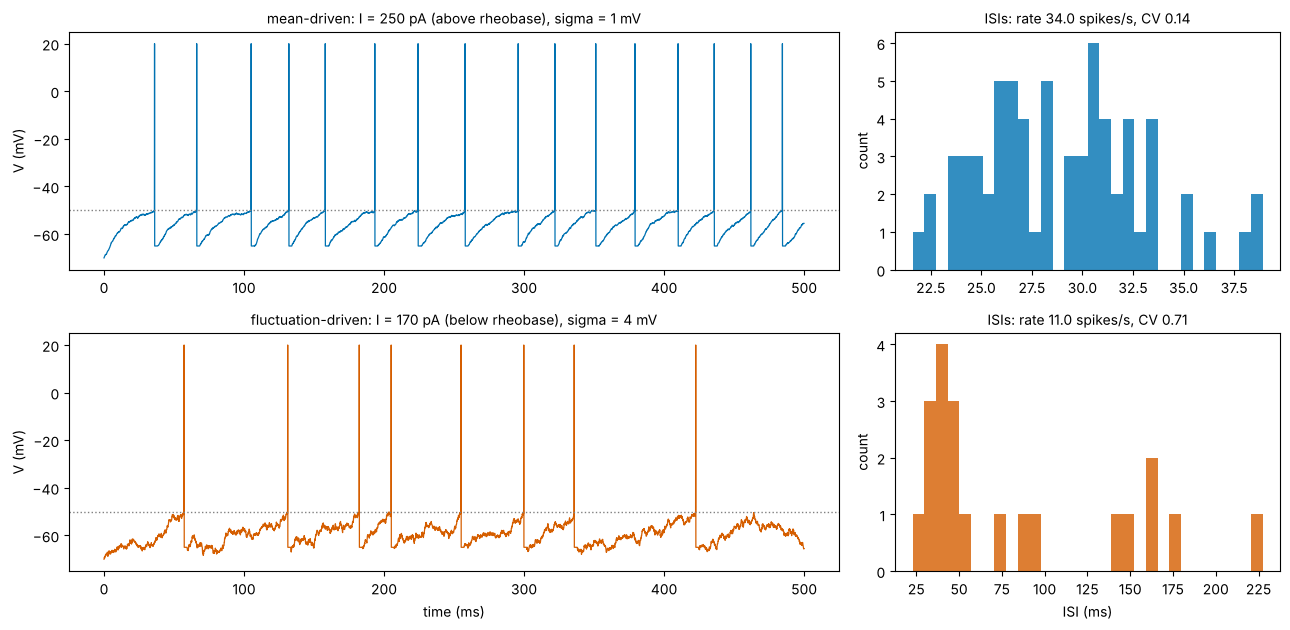

free membrane, sigma = 3 mV, dt = 0.01 ms: SD of V = 2.99 mV
free membrane, sigma = 3 mV, dt = 0.1 ms: SD of V = 3.03 mV
free membrane, sigma = 3 mV, dt = 1.0 ms: SD of V = 3.03 mV


In [6]:
t_n = np.arange(0, 2000, 0.1)                                               # (20000,) ms
fig, axes = plt.subplots(2, 2, figsize=(13, 6.4), gridspec_kw=dict(width_ratios=[2, 1]))
for row, (I_amp, sig, lab) in enumerate([(250, 1.0, 'mean-driven: I = 250 pA (above rheobase), sigma = 1 mV'),
                                          (170, 4.0, 'fluctuation-driven: I = 170 pA (below rheobase), sigma = 4 mV')]):
    V, sp = simulate_lif(np.full(t_n.size, float(I_amp)), 0.1, sigma=sig, rng=np.random.default_rng(row), **P)
    isi = np.diff(sp)
    Vplot = V.copy(); Vplot[np.searchsorted(t_n, sp) - 1] = 20.0
    axes[row, 0].plot(t_n[:5000], Vplot[:5000], color=PALETTE[row], lw=0.9)
    axes[row, 0].axhline(P['theta'], color='grey', ls=':', lw=1); axes[row, 0].set_ylabel('V (mV)'); axes[row, 0].set_ylim(-75, 25)
    axes[row, 0].set_title(lab, fontsize=10)
    axes[row, 1].hist(isi, bins=30, color=PALETTE[row], alpha=0.8)
    axes[row, 1].set_title(f'ISIs: rate {len(sp) / 2:.1f} spikes/s, CV {isi.std() / isi.mean():.2f}', fontsize=10); axes[row, 1].set_ylabel('count')
    print(f"{lab}: {len(sp)} spikes in 2 s, mean ISI {isi.mean():.1f} ms, CV {isi.std() / isi.mean():.2f}")
axes[1, 0].set_xlabel('time (ms)'); axes[1, 1].set_xlabel('ISI (ms)')
plt.tight_layout(); plt.show()

# Check the noise scaling: free membrane (no threshold), SD should be sigma for any dt.
for dt_chk in [0.01, 0.1, 1.0]:
    V, _ = simulate_lif(np.zeros(int(20000 / dt_chk)), dt_chk, sigma=3.0, rng=np.random.default_rng(5), **{**P, 'theta': 1e9})
    print(f"free membrane, sigma = 3 mV, dt = {dt_chk} ms: SD of V = {V[int(100 / dt_chk):].std():.2f} mV")

- **Mean-driven:** above rheobase, small noise only jitters a regular train: a narrow ISI histogram, low CV.
- **Fluctuation-driven:** below rheobase the deterministic LIF would be silent, but with 4 mV fluctuations it fires irregularly, with a broad ISI distribution and a CV of about 0.7, approaching Lesson 17's Poisson value of 1.
- With the $\sqrt{\Delta t}$ scaling, the membrane's SD is $\sigma$ whatever the step (up to the small Euler error at the largest step).

Now the F–I curve under noise. Fluctuations **smooth** the threshold: the rate becomes positive below rheobase and the infinitely steep onset disappears. This smoothing is why population models (Lesson 23) use a sigmoid rather than a hard threshold.

sigma = 2.0 mV: rate at 150 pA 1.7, at 200 pA (rheobase) 17.3, at 400 pA 74.0 spikes/s


sigma = 5.0 mV: rate at 150 pA 15.3, at 200 pA (rheobase) 24.0, at 400 pA 72.0 spikes/s


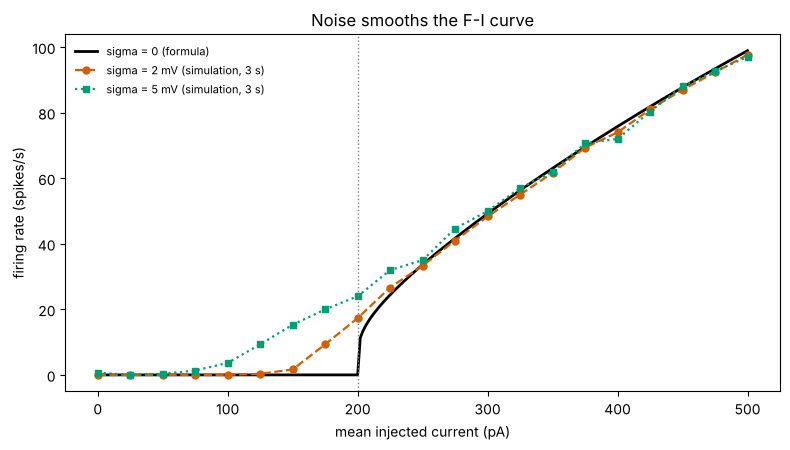

In [7]:
I_fi = np.arange(0, 501, 25)                                                 # (21,) pA
t_fi = np.arange(0, 3000, 0.1)                                               # (30000,) ms
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(I_grid[:251], lif_rate(I_grid[:251], **P), color='black', lw=2, label='sigma = 0 (formula)')
for k, sig in enumerate([2.0, 5.0]):
    r_ = [len(simulate_lif(np.full(t_fi.size, float(I_amp)), 0.1, sigma=sig, rng=np.random.default_rng(100 + j), **P)[1]) / 3.0 for j, I_amp in enumerate(I_fi)]
    ax.plot(I_fi, r_, MARKERS[k] + LINESTYLES[k + 1], color=PALETTE[k + 1], lw=1.6, ms=5, label=f'sigma = {sig:.0f} mV (simulation, 3 s)')
    print(f"sigma = {sig} mV: rate at 150 pA {r_[6]:.1f}, at 200 pA (rheobase) {r_[8]:.1f}, at 400 pA {r_[16]:.1f} spikes/s")
ax.axvline(I_rh, color='grey', ls=':', lw=1)
ax.set_xlabel('mean injected current (pA)'); ax.set_ylabel('firing rate (spikes/s)'); ax.set_title('Noise smooths the F-I curve')
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

**Poisson synaptic input.** Instead of a current, drive the neuron with $N$ excitatory synapses, each firing as an independent Poisson process; their sum is a Poisson process of total rate $\lambda$ (Lesson 18). Each input adds $J = 0.5$ mV. We check Campbell's theorem without a threshold, then let the neuron fire.

In [8]:
def simulate_lif_poisson(lam_hz, J, T_ms, dt=0.1, rng=None, E_L=-70.0, theta=-50.0, V_reset=-65.0, tau=20.0, t_ref=2.0):
    # LIF driven by Poisson input: each input makes V jump by J mV. lam_hz: total input rate (inputs/s).
    n = int(T_ms / dt); kicks = rng.poisson(lam_hz * dt / 1000, n) * J          # (n,) mV of jumps in each step
    V = np.empty(n); V[0] = E_L; spikes, ref_until = [], -np.inf
    for k in range(n - 1):
        if k * dt < ref_until:
            V[k + 1] = V_reset; continue
        V[k + 1] = V[k] - dt / tau * (V[k] - E_L) + kicks[k]
        if V[k + 1] >= theta:
            spikes.append((k + 1) * dt); V[k + 1] = V_reset; ref_until = (k + 1) * dt + t_ref
    return V, np.array(spikes)

J = 0.5
for lam in [1000, 2000]:
    V, _ = simulate_lif_poisson(lam, J, 20000, rng=np.random.default_rng(7), theta=1e9)
    Vs = V[1000:]
    print(f"no threshold, lambda = {lam} inputs/s, J = {J} mV: mean depolarisation {Vs.mean() + 70:.2f} mV (Campbell {J * lam * 0.02:.2f}), "
          f"SD {Vs.std():.2f} mV (Campbell {np.sqrt(J**2 * lam * 0.02 / 2):.2f})")
print()
lam_list = [1000, 1500, 2000, 2500, 3000, 4000]
for lam in lam_list:
    _, sp = simulate_lif_poisson(lam, J, 20000, rng=np.random.default_rng(int(lam)))
    isi = np.diff(sp)
    cv = isi.std() / isi.mean() if len(isi) > 2 else float('nan')
    counts = np.histogram(sp, bins=np.arange(0, 20001, 500))[0]             # spike counts in 500 ms windows
    ff = counts.var(ddof=1) / counts.mean() if counts.mean() > 0 else float('nan')
    print(f"lambda = {lam} inputs/s (mean V_inf = {-70 + J * lam * 0.02:.0f} mV): output {len(sp) / 20:.1f} spikes/s, ISI CV {cv:.2f}, Fano factor (500 ms) {ff:.2f}")

no threshold, lambda = 1000 inputs/s, J = 0.5 mV: mean depolarisation 9.93 mV (Campbell 10.00), SD 1.58 mV (Campbell 1.58)
no threshold, lambda = 2000 inputs/s, J = 0.5 mV: mean depolarisation 19.88 mV (Campbell 20.00), SD 2.23 mV (Campbell 2.24)



lambda = 1000 inputs/s (mean V_inf = -60 mV): output 0.0 spikes/s, ISI CV nan, Fano factor (500 ms) nan
lambda = 1500 inputs/s (mean V_inf = -55 mV): output 1.7 spikes/s, ISI CV 0.98, Fano factor (500 ms) 1.00


lambda = 2000 inputs/s (mean V_inf = -50 mV): output 17.6 spikes/s, ISI CV 0.46, Fano factor (500 ms) 0.19
lambda = 2500 inputs/s (mean V_inf = -45 mV): output 34.7 spikes/s, ISI CV 0.28, Fano factor (500 ms) 0.10


lambda = 3000 inputs/s (mean V_inf = -40 mV): output 50.0 spikes/s, ISI CV 0.25, Fano factor (500 ms) 0.07
lambda = 4000 inputs/s (mean V_inf = -30 mV): output 75.0 spikes/s, ISI CV 0.20, Fano factor (500 ms) 0.05


- Without a threshold, the mean and SD of the voltage match Campbell's theorem: the input rate sets the mean, and the jump size and rate together set the fluctuations.
- With a threshold: at $\lambda = 1000$ inputs/s (mean −60 mV) the neuron is silent; at 1500 inputs/s the **mean** (−55 mV) is still below threshold, yet the neuron fires, slowly and irregularly (CV about 1, Fano factor about 1). As the mean reaches and passes threshold, firing becomes faster and more **regular**: at 4000 inputs/s the CV is 0.2 and the Fano factor 0.05.
- Lesson 17 found Fano factors **above** 1 in mouse visual cortex. A single LIF with stationary Poisson input gives values at or below 1, so the extra variability must come from elsewhere: input rates that themselves vary from trial to trial (shared gain fluctuations, Lesson 17's doubly stochastic model), correlated inputs, or network dynamics.

#### Interactive version: noise amplitude

In [9]:
sig_list = [0.0, 1.0, 2.0, 3.0, 4.0, 6.0]
t_s = np.arange(0, 500, 0.1)                                                 # (5000,) ms
def noisy_trace(sig):
    V, sp = simulate_lif(np.full(t_s.size, 190.0), 0.1, sigma=sig, rng=np.random.default_rng(11), **P)
    Vp = V.copy(); Vp[np.searchsorted(t_s, sp) - 1] = 20.0
    return Vp, sp
Vp0, sp0 = noisy_trace(sig_list[0])
fig_s = go.Figure([go.Scatter(x=t_s, y=np.round(Vp0, 1), mode='lines', line=dict(color=PALETTE[0], width=1), name='V'),
                   go.Scatter(x=[0, 500], y=[P['theta']] * 2, mode='lines', line=dict(color='grey', dash='dot'), name='threshold')])
frames = []
for i, sig in enumerate(sig_list):
    Vp, sp = noisy_trace(sig)
    cv = np.std(np.diff(sp)) / np.mean(np.diff(sp)) if len(sp) > 2 else float('nan')
    frames.append(go.Frame(name=str(i), traces=[0], data=[go.Scatter(y=np.round(Vp, 1))],
                           layout=go.Layout(title=f'I = 190 pA (below rheobase), sigma = {sig} mV: {2 * len(sp)} spikes/s' + (f', ISI CV {cv:.2f}' if len(sp) > 2 else ''))))
fig_s.frames = frames
buttons, sliders = play_pause_and_slider(sig_list, prefix='sigma (mV) = ', duration=800)
fig_s.update_layout(title=frames[0].layout.title.text, xaxis=dict(title='time (ms)'), yaxis=dict(title='V (mV)', range=[-75, 25]),
                    template='plotly_white', width=850, height=450, updatemenus=buttons, sliders=sliders)
fig_s.show(config=PLOTLY_CONFIG)

# **Part 4: Event Handling, Time-Step Sensitivity and Model Assumptions**

**Event handling.** In `simulate_lif` the threshold is checked only at grid points, so a spike is placed at the first grid time after the true crossing, and the reset starts there. The error in each spike time is up to one step, and it **accumulates** from spike to spike, because each interval starts from a wrongly timed reset. Lesson 21's $O(\Delta t)$ accuracy of Euler is therefore not the whole story: for spiking models the event timing adds its own error.

Two improvements:
1. **Exact subthreshold update.** For constant input between grid points, $V_{n+1} = V_\infty + (V_n - V_\infty)e^{-\Delta t/\tau_m}$ (Lesson 21) has no integration error.
2. **Interpolated crossing.** When $V_n < \theta \le V_{n+1}$, estimate the crossing time by linear interpolation, $t^* = t_n + \Delta t\,\frac{\theta - V_n}{V_{n+1} - V_n}$, and start the refractory period and the next climb from $t^*$, not from the grid.

We compare the firing rate at 300 pA (formula: 49.20 spikes/s) for several step sizes.

formula: 49.199 spikes/s at 300 pA
 dt (ms)    Euler, grid events    exact update + interpolation
     1.0         50.000 (+0.80)                 49.188 (-0.0101)
     0.5         48.780 (-0.42)                 49.196 (-0.0026)
     0.2         49.015 (-0.18)                 49.198 (-0.0004)
     0.1         49.261 (+0.06)                 49.198 (-0.0001)
    0.05         49.140 (-0.06)                 49.198 (-0.0000)


    0.01         49.188 (-0.01)                 49.199 (-0.0000)

noise added WITHOUT the sqrt(dt) scaling (a common bug): SD of the free membrane
  dt =   1.0 ms: SD = 3.045 mV (should be 3 for every dt)


  dt =   0.1 ms: SD = 0.927 mV (should be 3 for every dt)


  dt =  0.01 ms: SD = 0.286 mV (should be 3 for every dt)


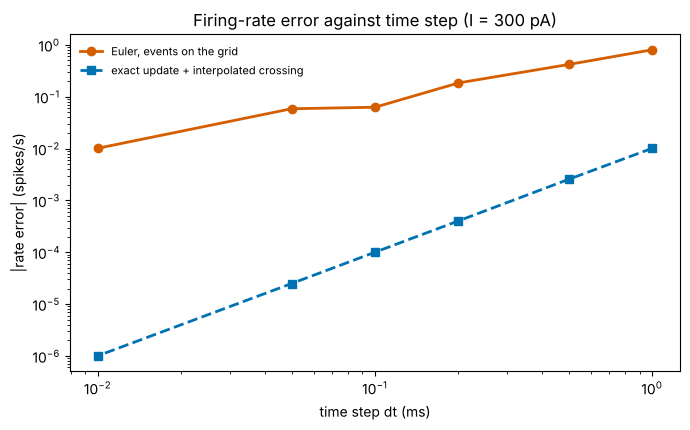

In [10]:
def rate_naive_euler(I_amp, dt, T=2000.0):
    _, sp = simulate_lif(np.full(int(T / dt), float(I_amp)), dt, **P)
    return (len(sp) - 1) / (sp[-1] - sp[0]) * 1000

def rate_exact_interp(I_amp, dt, T=2000.0, E_L=-70.0, theta=-50.0, V_reset=-65.0, tau=20.0, R=0.1, t_ref=2.0):
    # Exact update between grid points; interpolated threshold crossing; refractory and reset timed from the crossing.
    V_inf = E_L + R * I_amp; decay = np.exp(-dt / tau)
    t, V, spikes = 0.0, E_L, []
    while t < T:
        V_new = V_inf + (V - V_inf) * decay
        if V_new >= theta:
            t_star = t + dt * (theta - V) / (V_new - V)                       # interpolated crossing time
            spikes.append(t_star)
            t_restart = t_star + t_ref                                       # refractory ends here, at V_reset
            t = np.ceil(t_restart / dt) * dt                                  # next grid point
            V = V_inf + (V_reset - V_inf) * np.exp(-(t - t_restart) / tau)    # exact partial step from t_restart to the grid
        else:
            V, t = V_new, t + dt
    sp = np.array(spikes)
    return (len(sp) - 1) / (sp[-1] - sp[0]) * 1000

f_true = lif_rate(300, **P)
print(f"formula: {f_true:.3f} spikes/s at 300 pA\n{'dt (ms)':>8}{'Euler, grid events':>22}{'exact update + interpolation':>32}")
dts = [1.0, 0.5, 0.2, 0.1, 0.05, 0.01]
err_n, err_x = [], []
for dt_ in dts:
    rn, rx = rate_naive_euler(300, dt_), rate_exact_interp(300, dt_)
    err_n.append(abs(rn - f_true)); err_x.append(abs(rx - f_true))
    print(f"{dt_:>8}{rn:>15.3f} ({rn - f_true:+.2f}){rx:>23.3f} ({rx - f_true:+.4f})")

# Model assumption check: the wrong noise scaling (sigma * eta * dt / tau instead of sqrt) makes results depend on dt.
print("\nnoise added WITHOUT the sqrt(dt) scaling (a common bug): SD of the free membrane")
for dt_chk in [1.0, 0.1, 0.01]:
    n = int(20000 / dt_chk); rr = np.random.default_rng(3); V = np.empty(n); V[0] = -70.0
    eta = rr.standard_normal(n)
    for k in range(n - 1):
        V[k + 1] = V[k] - dt_chk / 20 * (V[k] + 70) + 3.0 * np.sqrt(2) * dt_chk / np.sqrt(20) * eta[k]     # wrong: dt instead of sqrt(dt)
    print(f"  dt = {dt_chk:>5} ms: SD = {V[int(100 / dt_chk):].std():.3f} mV (should be 3 for every dt)")

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.loglog(dts, err_n, 'o-', color=PALETTE[1], lw=2, label='Euler, events on the grid')
ax.loglog(dts, np.maximum(err_x, 1e-6), 's--', color=PALETTE[0], lw=2, label='exact update + interpolated crossing')
ax.set_xlabel('time step dt (ms)'); ax.set_ylabel('|rate error| (spikes/s)'); ax.set_title('Firing-rate error against time step (I = 300 pA)')
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

- With events on the grid, the rate is off by 0.8 spikes/s at $\Delta t = 1$ ms (still 1/20 of $\tau_m$, safe for the passive membrane), and the error shrinks only roughly in proportion to $\Delta t$, changing sign irregularly because spikes land on the grid in a pattern that depends on the step. With the exact update and an interpolated crossing, the error at $\Delta t = 1$ ms is 0.01 spikes/s, and it falls about four-fold each time the step is halved.
- Without the $\sqrt{\Delta t}$ scaling, the "same" noise has an SD that depends on the step size: a simulation result that changes when you change $\Delta t$ is a bug, not a finding. **Always rerun with half the step.**

**What the LIF assumes** (and where each assumption fails):

| Assumption | Reality | Consequence |
|---|---|---|
| Passive subthreshold membrane | voltage-dependent currents near threshold (Lesson 21's rising resistance) | rheobase and gain differ from passive predictions |
| Fixed, sharp threshold | threshold varies, rises during a burst (accommodation) | onset and late spikes differ |
| Instant spike and reset | the action potential takes about 1 ms; afterhyperpolarisation lasts tens of ms | spike shape and post-spike trajectory not modelled |
| No memory beyond the last spike | adaptation currents build up over many spikes | ISIs lengthen during a step (adaptation) |
| Current input | synapses change conductance, so input depends on $V$ | input effects shrink near reversal potentials |

The mini-lab tests the first, fourth and (indirectly) third.

# **Part 5: Mini-Lab — Does a Real Neuron Behave Like an LIF?**

**Data.** Lesson 21's recording (`18711001.abf`, pyABF sample files, MIT licence; cell type undocumented), 30 sweeps at 10 kHz. From 823 to 1323 ms each sweep injects a step of 0, 10, …, 290 pA. Lesson 21 measured $E_L = -67.9$ mV, $\tau_m = 17.5$ ms and $R_m = 222$ MΩ from the response to −100 pA.

- `V` (30, 15000): membrane potential, mV. `I` (30, 15000): injected current, pA. `t` (15000,): time, s.

**Questions.**
1. Detect the spikes. What are the rheobase, the spike threshold, the post-spike trough, the F–I curve and the interspike intervals?
2. What F–I curve does an LIF with the neuron's **own** passive parameters predict?
3. Can an LIF reproduce the measured F–I curve if its parameters are fitted, and are the fitted parameters believable?

In [11]:
import os, urllib.request
PATCH_FILE = 'patch_18711001_steps.npz'
for cand in [PATCH_FILE, os.path.join('..', '..', 'data', PATCH_FILE)]:
    if os.path.exists(cand):
        patch_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/e8996ac071a2a16c48d5b544ec3470816eecf49f/data/' + PATCH_FILE, PATCH_FILE)
    patch_path = PATCH_FILE
dp = np.load(patch_path)
V = dp['v_cmV'] / 100.0                                                     # (30, 15000) mV
I = dp['i_pA'].astype(float)                                                # (30, 15000) pA
fs = float(dp['fs_hz']); t = np.arange(V.shape[1]) / fs                     # (15000,) s
on = int(np.where(np.diff(I[5, int(0.5 * fs):]) != 0)[0][0] + 1 + int(0.5 * fs))   # onset of the second step
off = on + int(0.5 * fs)                                                    # 500 ms step
I_step = I[:, on + 10]                                                      # (30,) pA

def detect_spikes(v, fs, level=-10.0, dvdt_thr=10.0):
    # Spikes = upward crossings of `level` mV. Threshold = voltage where dV/dt first exceeds dvdt_thr (mV/ms) in the 3 ms before.
    # Trough = minimum between this spike and the next. Returns indices (samples), thresholds (mV), troughs (mV).
    up = np.where((v[1:] > level) & (v[:-1] <= level))[0] + 1
    dvdt = np.diff(v) * fs / 1000.0                                          # mV/ms
    thr, trough = [], []
    for k, u in enumerate(up):
        w = np.arange(max(0, u - int(0.003 * fs)), u)
        c = w[dvdt[w] > dvdt_thr]
        thr.append(v[c[0]] if len(c) else np.nan)
        nxt = up[k + 1] if k + 1 < len(up) else len(v)
        trough.append(v[u:nxt].min())
    return up, np.array(thr), np.array(trough)

rows = []
for s in range(30):
    up, thr, tro = detect_spikes(V[s, on:off], fs)
    isi = np.diff(up) / fs * 1000                                           # ms
    rows.append(dict(I=I_step[s], n=len(up), lat=up[0] / fs * 1000 if len(up) else np.nan,
                     thr1=thr[0] if len(up) else np.nan, trough1=tro[0] if len(up) > 1 else np.nan,
                     isi1=isi[0] if len(isi) else np.nan, isi_last=isi[-1] if len(isi) else np.nan))
n_spk = np.array([r['n'] for r in rows]); rate_count = n_spk / 0.5           # (30,) spikes/s over the 500 ms step
isi1 = np.array([r['isi1'] for r in rows]); f_init = 1000 / isi1              # (30,) spikes/s from the first ISI
thr1 = np.array([r['thr1'] for r in rows]); tro1 = np.array([r['trough1'] for r in rows])
i_first = np.argmax(n_spk > 0)
print(f"rheobase between {I_step[i_first - 1]:.0f} and {I_step[i_first]:.0f} pA")
print(f"first-spike threshold: median {np.nanmedian(thr1):.1f} mV (range {np.nanmin(thr1):.1f} to {np.nanmax(thr1):.1f});  trough after the first spike: median {np.nanmedian(tro1):.1f} mV")
print(f"\n{'I (pA)':>7}{'spikes':>8}{'rate, count (sp/s)':>20}{'latency (ms)':>14}{'1st ISI (ms)':>14}{'last ISI (ms)':>15}")
for s in range(i_first - 1, 30, 3):
    r = rows[s]
    print(f"{r['I']:>7.0f}{r['n']:>8}{rate_count[s]:>20.1f}{r['lat']:>14.1f}{r['isi1']:>14.1f}{r['isi_last']:>15.1f}")
two = n_spk >= 4
print(f"\nadaptation: last ISI / first ISI, median over sweeps with >= 4 spikes: {np.median(isi1[two] / np.array([r['isi_last'] for r in rows])[two]) ** -1:.2f}")

rheobase between 60 and 70 pA
first-spike threshold: median -34.6 mV (range -36.1 to -32.6);  trough after the first spike: median -40.4 mV

 I (pA)  spikes  rate, count (sp/s)  latency (ms)  1st ISI (ms)  last ISI (ms)
     60       0                 0.0           nan           nan            nan
     90       2                 4.0          51.5         186.0          186.0
    120       4                 8.0          33.9         122.0          165.1
    150       4                 8.0          24.2          73.6          210.6
    180       5                10.0          19.6          54.7          115.2
    210       5                10.0          15.8          48.2          234.6
    240       6                12.0          13.0          41.1           83.4
    270       7                14.0          11.4          34.3          165.4

adaptation: last ISI / first ISI, median over sweeps with >= 4 spikes: 2.55


In [12]:
# LIF with the neuron's own parameters (Lesson 21 passive fit + measured threshold and trough as reset).
E_L_c, tau_c, R_c = -67.9, 17.45, 0.222                                      # mV, ms, mV/pA (222 megaohm)
theta_c = float(np.nanmedian(thr1)); reset_c = float(np.nanmedian(tro1)); tref_c = 2.0
I_fine = np.linspace(0, 300, 301)
f_pred = lif_rate(I_fine, E_L=E_L_c, theta=theta_c, V_reset=reset_c, tau=tau_c, R=R_c, t_ref=tref_c)
I_rh_pred = (theta_c - E_L_c) / R_c
print(f"LIF with measured parameters: rheobase {I_rh_pred:.0f} pA (measured {I_step[i_first - 1]:.0f}-{I_step[i_first]:.0f} pA); "
      f"rate at 290 pA {lif_rate(290, E_L=E_L_c, theta=theta_c, V_reset=reset_c, tau=tau_c, R=R_c, t_ref=tref_c):.0f} spikes/s "
      f"(measured: {f_init[-1]:.0f} from the first ISI, {rate_count[-1]:.0f} averaged over the step)")

# Fit an LIF to the initial-rate F-I curve (first ISI), with theta fixed at the measured value; profile over tau (Lesson 11's flat directions).
fit_mask = n_spk >= 2
I_fit, f_fit = I_step[fit_mask], f_init[fit_mask]
profile = []
for tau_try in [17.45, 50.0, 100.0, 200.0, 500.0]:
    res = least_squares(lambda p: lif_rate(I_fit, E_L=E_L_c, theta=theta_c, V_reset=p[1], tau=tau_try, R=p[0], t_ref=tref_c) - f_fit,
                        x0=[0.3, -50.0], bounds=([0.05, -120.0], [3.0, theta_c - 0.1]))
    rmse = np.sqrt(np.mean(res.fun**2))
    profile.append((tau_try, res.x[0], res.x[1], rmse))
    print(f"tau fixed at {tau_try:>6.1f} ms: best R = {res.x[0] * 1e3:>4.0f} megaohm, V_reset = {res.x[1]:>7.1f} mV, RMSE {rmse:.2f} spikes/s, "
          f"implied rheobase {(theta_c - E_L_c) / res.x[0]:.0f} pA")

LIF with measured parameters: rheobase 150 pA (measured 60-70 pA); rate at 290 pA 201 spikes/s (measured: 35 from the first ISI, 14 averaged over the step)
tau fixed at   17.4 ms: best R =  193 megaohm, V_reset =  -120.0 mV, RMSE 7.34 spikes/s, implied rheobase 172 pA
tau fixed at   50.0 ms: best R =  328 megaohm, V_reset =   -84.0 mV, RMSE 2.21 spikes/s, implied rheobase 101 pA
tau fixed at  100.0 ms: best R =  400 megaohm, V_reset =   -62.5 mV, RMSE 1.52 spikes/s, implied rheobase 83 pA
tau fixed at  200.0 ms: best R =  467 megaohm, V_reset =   -50.5 mV, RMSE 1.24 spikes/s, implied rheobase 71 pA
tau fixed at  500.0 ms: best R =  537 megaohm, V_reset =   -41.9 mV, RMSE 1.09 spikes/s, implied rheobase 62 pA


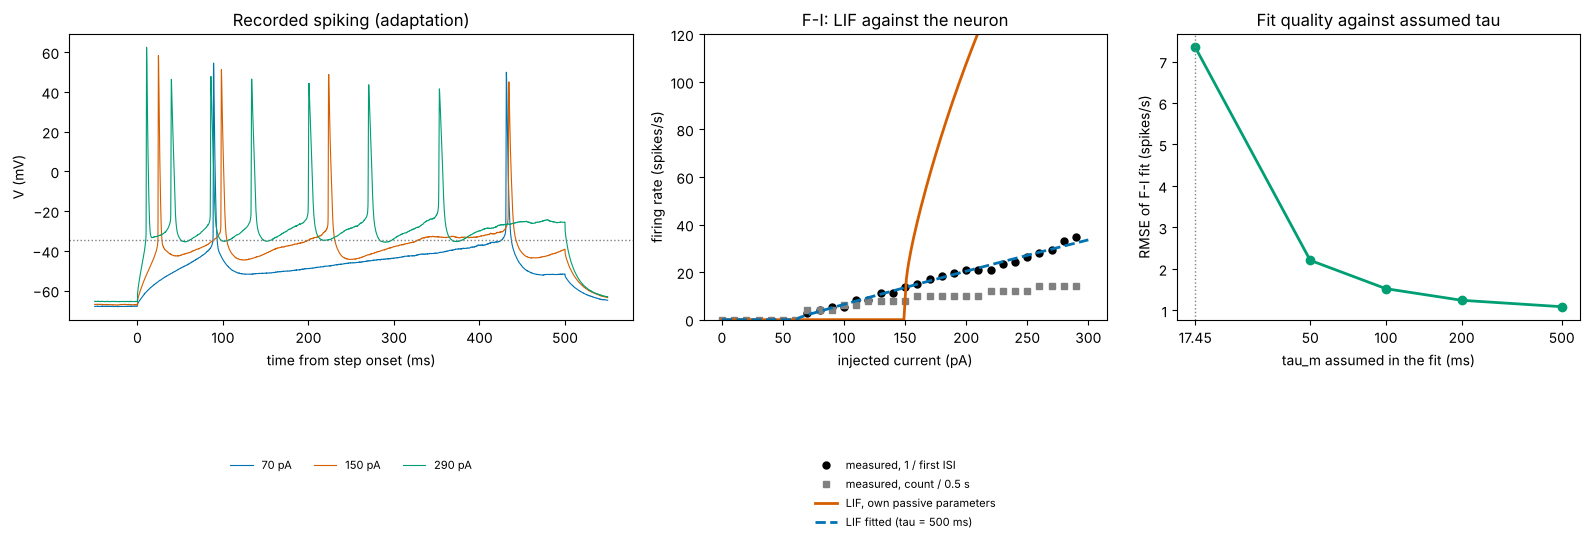

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6.5), gridspec_kw=dict(width_ratios=[1.4, 1, 1]))
ax = axes[0]
for k, s in enumerate([7, 15, 29]):
    seg = slice(on - int(0.05 * fs), off + int(0.05 * fs))
    ax.plot((t[seg] - t[on]) * 1000, V[s, seg] + 0 * k, color=PALETTE[k], lw=0.8, label=f'{I_step[s]:.0f} pA')
ax.axhline(theta_c, color='grey', ls=':', lw=1)
ax.set_xlabel('time from step onset (ms)'); ax.set_ylabel('V (mV)'); ax.set_title('Recorded spiking (adaptation)')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.45), ncol=3)
ax = axes[1]
ax.plot(I_step, f_init, 'o', color='black', ms=5, label='measured, 1 / first ISI')
ax.plot(I_step, rate_count, 's', color='grey', ms=4, label='measured, count / 0.5 s')
ax.plot(I_fine, f_pred, '-', color=PALETTE[1], lw=2, label='LIF, own passive parameters')
best = profile[-1]
ax.plot(I_fine, lif_rate(I_fine, E_L=E_L_c, theta=theta_c, V_reset=best[2], tau=best[0], R=best[1], t_ref=tref_c), '--', color=PALETTE[0], lw=2, label=f'LIF fitted (tau = {best[0]:.0f} ms)')
ax.set_ylim(0, 120); ax.set_xlabel('injected current (pA)'); ax.set_ylabel('firing rate (spikes/s)'); ax.set_title('F-I: LIF against the neuron')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.45), ncol=1)
ax = axes[2]
taus = [p[0] for p in profile]; rm = [p[3] for p in profile]
ax.semilogx(taus, rm, 'o-', color=PALETTE[2], lw=2)
ax.set_xticks(taus); ax.set_xticklabels([f'{x:g}' for x in taus]); ax.minorticks_off()
ax.axvline(tau_c, color='grey', ls=':', lw=1)
ax.set_xlabel('tau_m assumed in the fit (ms)'); ax.set_ylabel('RMSE of F-I fit (spikes/s)'); ax.set_title('Fit quality against assumed tau')
plt.tight_layout(); plt.show()

**Reading the mini-lab.**
- **Measured.** The neuron starts firing between 60 and 70 pA; its first spike starts at a threshold of about −35 mV and is followed by a trough near −40 mV. Its rate rises slowly with current: at 290 pA the first interval corresponds to about 34 spikes/s and the average over the 500 ms step to 14 spikes/s, because the intervals **lengthen** through the step (the last interval is typically about 2–3 times the first: **spike-frequency adaptation**).
- **LIF with the neuron's own parameters.** With $E_L$, $\tau_m$ and $R_m$ from Lesson 21 and the measured threshold and trough, the LIF needs about 150 pA to fire (twice the real rheobase) and then fires far too fast: about 200 spikes/s at 290 pA, six times the real initial rate, because a reset only 6 mV below threshold leaves very little to climb. Both errors have causes we have already seen: the real neuron's effective resistance rises near threshold (Lesson 21: 1.9 times the passive value at 60 pA), which lowers the real rheobase; and slow post-spike currents (the afterhyperpolarisation and adaptation) hold the real neuron back after each spike, which the instant reset ignores.
- **LIF with fitted parameters.** Fitting $R_m$ and $V_{\text{reset}}$ to the initial-rate F–I curve works badly with the real $\tau_m$ (RMSE about 7 spikes/s, with the reset driven to the −120 mV bound of the search, which no neuron has). The fit improves steadily as $\tau_m$ is allowed to grow, reaching about 1.1 spikes/s at $\tau_m = 500$ ms with $R_m \approx 530$ MΩ. Such parameters reproduce the curve but describe no membrane: they are **phenomenological**. The fit is also **sloppy** (Lessons 11 and 15): many combinations of $\tau_m$, $R_m$ and $V_{\text{reset}}$ fit almost equally well.
- **What is missing.** Adaptation (intervals lengthen within a step), a threshold that rises during a train (from about −35 to −20 mV at high currents), and voltage-dependent currents below threshold. Standard extensions add an adaptation variable $w$ with $\tau_w\,dw/dt = -w$ and $w \leftarrow w + b$ at each spike (the adaptive LIF; see the exercise bonus), a dynamic threshold, or an exponential spike-initiation term (the AdEx model). Each adds a differential equation: coupled ODEs, the subject of Lesson 23.

**Limitations.** One neuron of undocumented type; thresholds estimated from a 10 kHz recording with a simple dV/dt criterion; the initial rate from one interval per sweep is noisy; the refractory period was assumed (2 ms), not measured.

# **Part 6: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Threshold, reset, refractoriness | point-neuron models of cortical, hippocampal and cerebellar cells; fitting F–I curves | spiking neural networks (SNNs); neuromorphic hardware (Loihi, SpiNNaker) |
| Rheobase and F–I curve | classifying neurons (type I and II); comparing cell types and disease models | the F–I curve as an activation function; rate-coded networks |
| Noise-driven firing | irregular cortical firing, ISI CV near 1; balanced excitation and inhibition | stochastic neurons; noise as regularisation; dropout-like variability |
| Poisson and Gaussian drive | the diffusion approximation; mean-field theories of networks (Brunel, 2000) | event-based sensors and inputs (dynamic vision sensors) |
| Event handling, time step | simulators (NEST, Brian, NEURON) and their spike-timing precision | training SNNs with surrogate gradients through the non-differentiable threshold |
| Model assumptions | adaptive and exponential IF models (AdEx), generalised LIF models fitted to Allen cell-type data | choosing the simplest model that captures the behaviour you need |

# **Part 7: Summary, Exit Ticket and Lesson 23 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| LIF | $\tau_m\,dV/dt = -(V - E_L) + R_m I$; if $V \ge \theta$: spike, $V \leftarrow V_{\text{reset}}$, wait $t_{\text{ref}}$ | a hybrid system: ODE plus an event rule |
| Rheobase | $I_{\text{rh}} = (\theta - E_L)/R_m$ | fires iff $V_\infty > \theta$ |
| ISI and F–I | $T = t_{\text{ref}} + \tau_m\ln\frac{V_\infty - V_{\text{reset}}}{V_\infty - \theta}$, $f = 1/T$ | zero below rheobase, infinitely steep onset, capped at $1/t_{\text{ref}}$ |
| Gaussian drive | $+\,\sigma\sqrt{2\Delta t/\tau_m}\,\eta_n$ (Euler–Maruyama) | noise scales with $\sqrt{\Delta t}$; free SD $= \sigma$ |
| Poisson drive | jumps $J$ at rate $\lambda$: mean $J\lambda\tau_m$, variance $J^2\lambda\tau_m/2$ | fluctuation-driven firing is irregular (CV near 1) |
| Event handling | interpolate the crossing; time the reset from it | grid-locked events add their own error |
| Model checking | compare rheobase, F–I and ISIs with data | real neurons adapt; fitted LIF parameters can be phenomenological |

**Exit ticket.** An LIF has $E_L = -65$ mV, $\theta = -50$ mV, $V_{\text{reset}} = -60$ mV, $R_m = 150$ MΩ, $\tau_m = 15$ ms, $t_{\text{ref}} = 3$ ms. (a) What is its rheobase? (b) What is its firing rate at 200 pA? (c) A student adds noise as `sigma * np.random.randn() * dt / tau`. What goes wrong?

*(Answers: (a) 15 mV / 150 MΩ = 100 pA. (b) $V_\infty = -65 + 30 = -35$ mV; $T = 3 + 15\ln(25/15) = 3 + 7.66 = 10.66$ ms, so about 94 spikes/s. (c) The noise variance per step scales with $\Delta t^2$ instead of $\Delta t$, so the fluctuations shrink as the step is refined and the results depend on the time step; the term must be `sigma * np.sqrt(2 * dt / tau) * eta`.)*

**Lesson 23 — Coupled ODEs and Wilson–Cowan.** Real neurons need more than one variable (adaptation, gating), and populations interact. Lesson 23 writes systems of coupled equations as state vectors, draws phase planes with nullclines and fixed points, linearises with the Jacobian (Lesson 6's eigenvalues return), and studies the Wilson–Cowan model of interacting excitatory and inhibitory populations, including oscillations.

**Further reading.** W. Gerstner, W. M. Kistler, R. Naud and L. Paninski, *Neuronal Dynamics* (2014), Chapters 1, 6 and 8 (free online); P. Dayan and L. F. Abbott, *Theoretical Neuroscience* (2001), Section 5.4; N. Brunel and M. C. W. van Rossum, "Lapicque's 1907 paper: from frogs to integrate-and-fire", *Biological Cybernetics* 97 (2007); R. Brette and W. Gerstner, "Adaptive exponential integrate-and-fire model", *Journal of Neurophysiology* 94 (2005); the Neuromatch Academy tutorials on the LIF neuron (W0D3/W2D3), CC-BY.